In [1]:
!pip install -q onnx onnxruntime fastapi python-multipart

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import os
import onnx
import onnxruntime as ort

from PIL import Image, ImageDraw, ImageFont
from google.colab import files
from IPython.display import display

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nSelected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Running on CPU.")

PyTorch Version: 2.14.1+cpu
Torchvision Version: 0.29.1+cpu

Selected Device: cpu
GPU unavailable. Running on CPU.


In [3]:
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

model = model.to(device)
model.eval()

categories = weights.meta["categories"]
preprocess = weights.transforms()

print("ResNet-18 Model Loaded Successfully!")
print("Number of Classes:", len(categories))
print("Model Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 57.3MB/s]


ResNet-18 Model Loaded Successfully!
Number of Classes: 1000
Model Device: cpu


Saving traffic.jpg to traffic.jpg
Uploaded Image: traffic.jpg


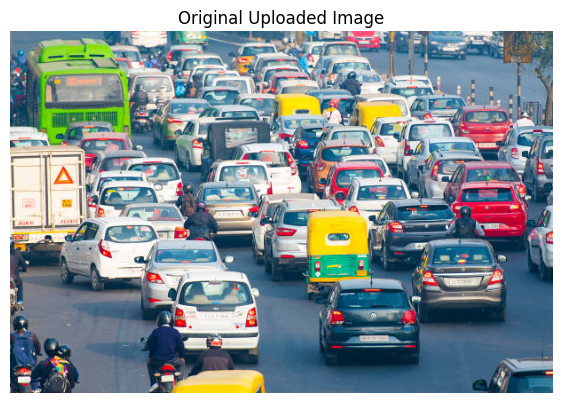

In [4]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

original_image = Image.open(image_path).convert("RGB")

print("Uploaded Image:", image_path)

plt.figure(figsize=(7, 6))
plt.imshow(original_image)
plt.title("Original Uploaded Image")
plt.axis("off")
plt.show()

In [17]:
input_tensor = preprocess(original_image).unsqueeze(0).to(device)

if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.inference_mode():
    outputs = model(input_tensor)
    probabilities = torch.nn.functional.softmax(outputs, dim=1)

if device.type == "cuda":
    torch.cuda.synchronize()

gpu_time = time.perf_counter() - start_time

top_prob, top_indices = torch.topk(probabilities, 5)

top_results = []

for probability, index in zip(top_prob[0], top_indices[0]):
    top_results.append({
        "Class": categories[index.item()],
        "Confidence (%)": probability.item() * 100
    })

results_df = pd.DataFrame(top_results)

print("IMAGE CLASSIFICATION RESULTS")
display(results_df.round(2))

print(f"GPU/Device Inference Time: {gpu_time*1000:.2f} ms")

IMAGE CLASSIFICATION RESULTS


,Class,Confidence (%)
0,cab,86.19
1,minibus,4.15
2,ambulance,1.26
3,toyshop,1.26
4,golfcart,0.66


GPU/Device Inference Time: 99.48 ms


FINAL DETECTED IMAGE


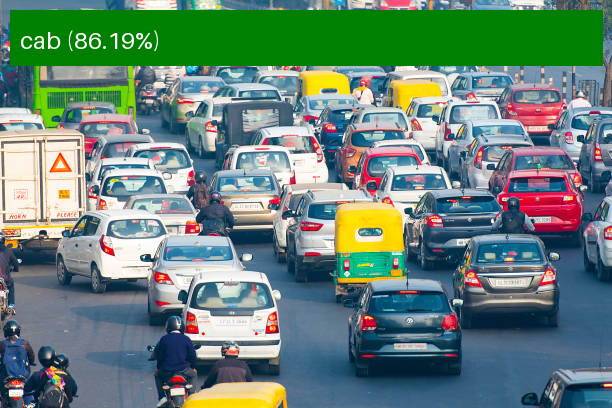

Detected image saved successfully!


In [18]:
predicted_class = top_results[0]["Class"]
confidence = top_results[0]["Confidence (%)"]

output_image = original_image.copy()

draw = ImageDraw.Draw(output_image)

font = ImageFont.load_default(size=24)

label = f"{predicted_class} ({confidence:.2f}%)"

draw.rectangle(
    [(10, 10), (original_image.width - 10, 65)],
    fill="green"
)

draw.text(
    (20, 25),
    label,
    fill="white",
    font=font
)

print("FINAL DETECTED IMAGE")
display(output_image)

output_image.save("Skill3_Detected_Image.jpg")

print("Detected image saved successfully!")

In [19]:
dummy_input = torch.randn(1, 3, 224, 224).to(device)

model.eval()

torch.onnx.export(
    model,
    dummy_input,
    "visionport_model.onnx",
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

onnx_model = onnx.load("visionport_model.onnx")

onnx.checker.check_model(onnx_model)

print("ONNX Conversion Successful!")
print("Model File: visionport_model.onnx")

/tmp/ipykernel_707/4271340885.py:5: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX Conversion Successful!
Model File: visionport_model.onnx


In [21]:
session = ort.InferenceSession(
    "visionport_model.onnx",
    providers=["CPUExecutionProvider"]
)

onnx_input = input_tensor.detach().cpu().numpy()

start_time = time.perf_counter()

onnx_output = session.run(
    ["output"],
    {"input": onnx_input}
)[0]

onnx_time = time.perf_counter() - start_time

onnx_probabilities = torch.softmax(
    torch.tensor(onnx_output), dim=1
)

onnx_confidence, onnx_index = torch.max(
    onnx_probabilities, dim=1
)

print("ONNX Prediction:", categories[onnx_index.item()])
print("Confidence:", round(onnx_confidence.item()*100, 2), "%")
print("ONNX Inference Time:", round(onnx_time*1000, 2), "ms")

ONNX Prediction: cab
Confidence: 86.19 %
ONNX Inference Time: 94.46 ms


In [22]:
benchmark_results = []

for name, function in [
    ("PyTorch", lambda: model(input_tensor)),
    ("ONNX", lambda: session.run(
        ["output"], {"input": onnx_input}
    ))
]:

    for i in range(30):
        if device.type == "cuda" and name == "PyTorch":
            torch.cuda.synchronize()

        start = time.perf_counter()

        function()

        if device.type == "cuda" and name == "PyTorch":
            torch.cuda.synchronize()

        elapsed = (time.perf_counter() - start) * 1000

        benchmark_results.append({
            "Model": name,
            "Latency (ms)": elapsed
        })

benchmark_df = pd.DataFrame(benchmark_results)

performance = benchmark_df.groupby("Model")["Latency (ms)"].agg(
    ["mean", "min", "max"]
)

print("MODEL PERFORMANCE COMPARISON")
display(performance.round(3))

MODEL PERFORMANCE COMPARISON


,mean,min,max
Model,,,
ONNX,99.117,56.001,227.697
PyTorch,424.710,178.396,811.951


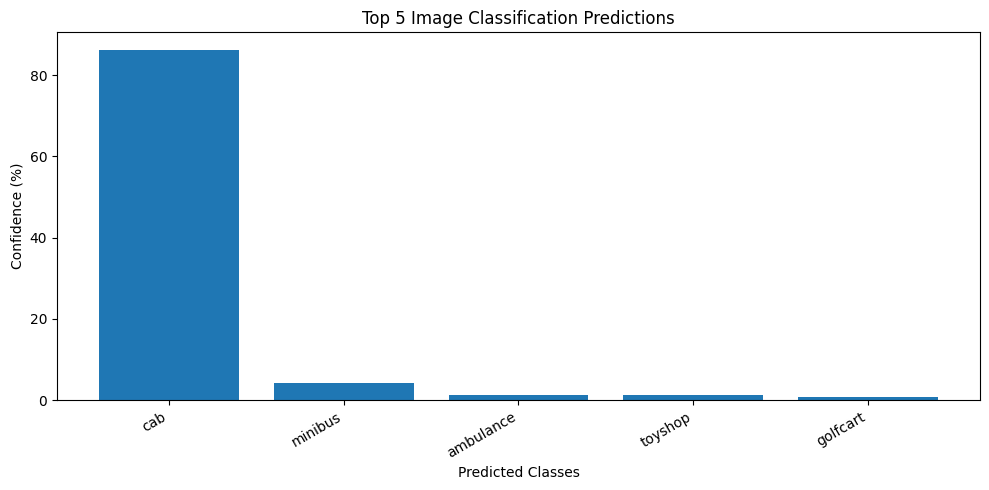

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(
    [x["Class"] for x in top_results],
    [x["Confidence (%)"] for x in top_results]
)

plt.title("Top 5 Image Classification Predictions")
plt.xlabel("Predicted Classes")
plt.ylabel("Confidence (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

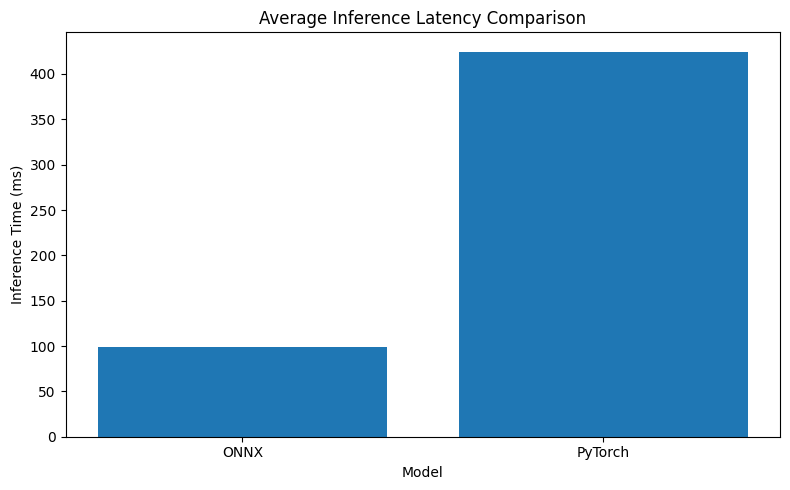

In [24]:
plt.figure(figsize=(8, 5))

plt.bar(
    performance.index,
    performance["mean"]
)

plt.title("Average Inference Latency Comparison")
plt.xlabel("Model")
plt.ylabel("Inference Time (ms)")
plt.tight_layout()
plt.show()

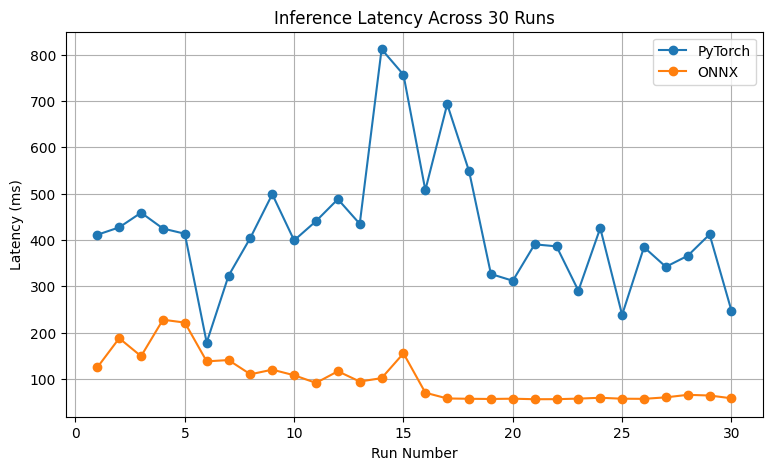

In [25]:
plt.figure(figsize=(9, 5))

for name in benchmark_df["Model"].unique():
    values = benchmark_df[
        benchmark_df["Model"] == name
    ]["Latency (ms)"]

    plt.plot(
        range(1, len(values) + 1),
        values,
        marker="o",
        label=name
    )

plt.title("Inference Latency Across 30 Runs")
plt.xlabel("Run Number")
plt.ylabel("Latency (ms)")
plt.legend()
plt.grid(True)
plt.show()

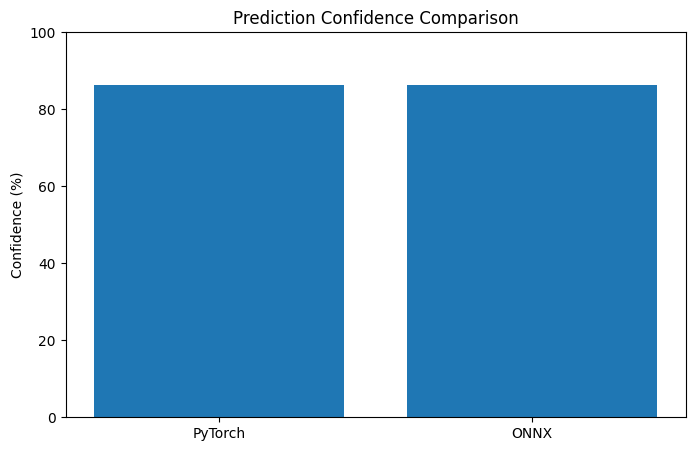

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["PyTorch", "ONNX"],
    [
        top_results[0]["Confidence (%)"],
        onnx_confidence.item() * 100
    ]
)

plt.title("Prediction Confidence Comparison")
plt.ylabel("Confidence (%)")
plt.ylim(0, 100)
plt.show()

In [27]:
print("TENSORRT AVAILABILITY CHECK")

try:
    import tensorrt as trt
    print("TensorRT Version:", trt.__version__)
    print("TensorRT is available.")
except ImportError:
    print("TensorRT is not installed in this Colab runtime.")
    print("ONNX conversion and inference benchmarking were completed.")

print("\nGPU INFORMATION")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU detected.")

TENSORRT AVAILABILITY CHECK
TensorRT is not installed in this Colab runtime.
ONNX conversion and inference benchmarking were completed.

GPU INFORMATION
No GPU detected.


In [28]:
from fastapi import FastAPI, UploadFile, File
from io import BytesIO

app = FastAPI(title="VisionPort Skill 3")

@app.get("/")
def home():
    return {
        "project": "VisionPort",
        "skill": "Skill 3 - Model Optimization",
        "status": "Running"
    }

@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model": "ResNet18",
        "format": "ONNX",
        "device": str(device)
    }

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    image = Image.open(
        BytesIO(await file.read())
    ).convert("RGB")

    tensor = preprocess(image).unsqueeze(0).cpu().numpy()

    prediction = session.run(
        ["output"],
        {"input": tensor}
    )[0]

    probs = torch.softmax(
        torch.tensor(prediction), dim=1
    )[0]

    confidence, index = torch.max(probs, dim=0)

    return {
        "prediction": categories[index.item()],
        "confidence": round(confidence.item()*100, 2),
        "model": "ResNet18 ONNX"
    }

print("FastAPI application created successfully!")
print("Endpoints: / , /health , /predict")

FastAPI application created successfully!
Endpoints: / , /health , /predict


In [29]:
!pip install -q pyngrok uvicorn